# 04 | Delta, 8B specificity, and comparison with the borderline scale

This follow-up uses the same sample and the epochs from the main preprocessing pipeline. The historical 28-participant comparison uses a separate protocol.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [1]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## Participant-level features

Summarize relative power across epochs. To assess sensitivity, exclude the two frontopolar electrodes or trim the highest 5% of epochs by relative delta power.


DeltaIQR 0.7
First 0.683
Last 0.68
NoFp 0.525
LogDelta 0.553
Trim5 0.697
partial/other, mean, both: 0.689 0.534 0.522
LOO: [np.float64(0.685), np.float64(0.728), np.float64(0.696), np.float64(0.676), np.float64(0.729), np.float64(0.654), np.float64(0.744), np.float64(0.672), np.float64(0.704), np.float64(0.739), np.float64(0.695), np.float64(0.703), np.float64(0.678), np.float64(0.678), np.float64(0.673), np.float64(0.764), np.float64(0.654), np.float64(0.694), np.float64(0.714)]


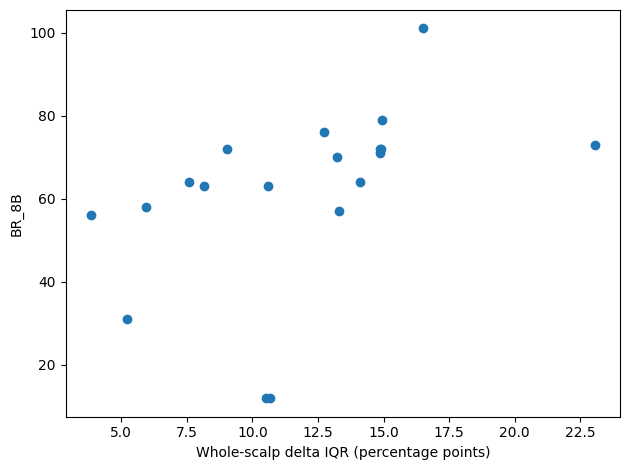

['OtherBR'] partial rho and approximate nominal p (np.float64(0.6888361540131663), np.float64(0.0015697153592085689))
['MeanDelta'] partial rho and approximate nominal p (np.float64(0.5338826471821623), np.float64(0.022484944689894874))
['MeanDelta', 'OtherBR'] partial rho and approximate nominal p (np.float64(0.5216445948324533), np.float64(0.03174425700041969))
Adjusted mean & rejected time 0.5397635254485268
Delta / 8B paired CI [0.36330378 0.89189799]


In [2]:
from scipy.signal import welch
from scipy.stats import iqr
bands = {'Delta':(2,4), 'Theta':(4,8), 'Alpha':(8,13), 'LowBeta':(13,20), 'HighBeta':(20,30), 'Beta':(13,30)}
def epoch_features(path):
    with np.load(path) as data:
        names = [c.split('-')[0] for c in data['channels']]
        freq, psd = welch(data['eeg'].astype(float), fs=500, nperseg=500, noverlap=250)
        rows = {}
        regions = {'Global':names,'Occipital':['O1','O2'],'Parietal':['P3','Pz','P4'],
                   'NoFp':[c for c in names if c not in ('Fp1','Fp2')]}
        regions.update({c:[c] for c in names})
        for region, channels in regions.items():
            power = psd[:,[names.index(c) for c in channels]].mean(1)
            total = power[:,(freq>=2)&(freq<30)].sum(1)
            for band,(low,high) in bands.items():
                value = power[:,(freq>=low)&(freq<high)].sum(1)
                rows[f'{region}-{band}'] = 100*value/total
                if band=='Delta':
                    rows[f'{region}-DeltaDB'] = 10*np.log10(value)
        return pd.DataFrame(rows).assign(start=data['start_sample'], subject=path.stem)

assert len(ids)==19, 'Run notebook 01 in full first.'
feature_path=work/'epoch_features.pkl'
if not feature_path.exists():
    pd.concat([epoch_features(p) for p in sorted((work/'out').glob('Subject_*.npz'))],ignore_index=True).to_pickle(feature_path)
epochs=pd.read_pickle(feature_path)
group=epochs[epochs.subject.isin(ids)].groupby('subject',sort=True)
scales=scores.loc[ids,[c for c in scores if c.startswith(('BR_','RAW_')) or c.endswith('_Score')]]
scales=scales.loc[:,scales.nunique()>1]
assert scales.shape==(19,57)
from scipy.stats import false_discovery_control
def ranked_unit(values):
    ranks=rankdata(values,axis=0)
    ranks-=ranks.mean(axis=0)
    return ranks/np.maximum(np.linalg.norm(ranks,axis=0),1e-20)
def scan(features,outcomes,permutations=20000,seed=23):
    outcomes=outcomes.loc[features.index]
    x=ranked_unit(features.to_numpy()); y=ranked_unit(outcomes.to_numpy())
    observed=x.T@y
    hits=np.ones_like(observed); maxima=[]
    rng=np.random.default_rng(seed)
    for start in range(0,permutations,50):
        order=np.array([rng.permutation(len(x)) for _ in range(min(50,permutations-start))])
        sims=np.abs(x.T@y[order])
        hits+=(sims>=np.abs(observed)-1e-12).sum(0)
        maxima.extend(sims.max(axis=(1,2)))
    p=hits/(permutations+1); q=false_discovery_control(p.ravel()).reshape(p.shape)
    pmax=(1+permutations-np.searchsorted(np.sort(maxima),np.abs(observed)-1e-12))/(permutations+1)
    index=pd.MultiIndex.from_product([features.columns,outcomes.columns],names=['feature','score'])
    return pd.DataFrame(dict(rho=observed.ravel(),p=p.ravel(),q=q.ravel(),pmax=pmax.ravel()),index=index)
def partial(x,y,*controls):
    design=np.column_stack([np.ones(len(x)),*[rankdata(z) for z in controls]])
    ranked=rankdata(np.column_stack([x,y]),axis=0)
    residual=ranked-design@np.linalg.lstsq(design,ranked,rcond=None)[0]
    return np.corrcoef(residual.T)[0,1]

individual=[]
for sid,b in epochs.groupby('subject'):
    x=b['Global-Delta'].to_numpy(); h=len(x)//2
    individual.append((sid,iqr(x),x.mean(),iqr(x[:h]),iqr(x[-h:]),iqr(b['NoFp-Delta']),iqr(b['Global-DeltaDB']),iqr(np.sort(x)[:len(x)-int(np.ceil(.05*len(x)))]),iqr(b['F8-Delta']),b['Parietal-Alpha'].median(),b['Parietal-Delta'].median()))
features=pd.DataFrame(individual,columns=['subject','DeltaIQR','MeanDelta','First','Last','NoFp','LogDelta','Trim5','F8IQR','ParietalAlpha','ParietalDelta']).set_index('subject')
features.to_csv('direct_features.csv')
a=features.loc[ids].join(scales)
br=[c for c in scales if c.startswith('BR_') and c not in ('BR_X','BR_Y','BR_Z','BR_8B')]
a['OtherBR']=a[br].mean(axis=1)
for name in ['DeltaIQR','First','Last','NoFp','LogDelta','Trim5']:
    print(name, spearmanr(a[name],a.BR_8B).statistic.round(3))
print('partial/other, mean, both:',*[round(partial(a.DeltaIQR,a.BR_8B,*z),3) for z in [[a.OtherBR],[a.MeanDelta],[a.OtherBR,a.MeanDelta]]])
print('LOO:',[round(spearmanr(a.drop(i).DeltaIQR,a.drop(i).BR_8B).statistic,3) for i in ids])
plt.scatter(a.DeltaIQR,a.BR_8B);plt.xlabel('Whole-scalp delta IQR (percentage points)');plt.ylabel('BR_8B');figure('04_delta_8B')
from scipy.stats import t as student_t
def partial_summary(data,controls):
    r=partial(data.DeltaIQR,data.BR_8B,*[data[k] for k in controls])
    df=len(data)-len(controls)-2
    return r,2*student_t.sf(abs(r)*np.sqrt(df/(1-r*r)),df)
for controls in [['OtherBR'],['MeanDelta'],['MeanDelta','OtherBR']]:
    print(controls,'partial rho and approximate nominal p',partial_summary(a,controls))
quality=pd.read_csv(work/'out/quality.csv').set_index('subject')
print('Adjusted mean & rejected time',partial(a.DeltaIQR,a.BR_8B,a.MeanDelta,100-quality.loc[ids,'percent']))
rng=np.random.default_rng(123);values=a[['DeltaIQR','BR_8B']].to_numpy()
samples=values[rng.integers(0,len(ids),(20000,len(ids)))]
r=rankdata(samples,axis=1);r-=r.mean(1,keepdims=True);r/=np.maximum(np.linalg.norm(r,axis=1,keepdims=True),1e-18)
print('Delta / 8B paired CI',np.percentile((r[:,:,0]*r[:,:,1]).sum(1),[2.5,97.5]))

## Direct comparison and reinstating recordings

Bootstrap participants jointly across both features and both scores. Summarize parietal power using the median of Welch-based ratios for P3/Pz/P4. The 28-participant comparison is sensitive to the denominator of relative power.


In [3]:
from scipy.stats import rankdata
measures=['DeltaIQR','ParietalAlpha']
def pair_rhos(frame):return frame[measures+['BR_8B','BR_C']].corr(method='spearman').loc[measures,['BR_8B','BR_C']]
display(pair_rhos(a))
values=a[measures+['BR_8B','BR_C']].to_numpy()
rng=np.random.default_rng(54); differences=[]
for _ in range(400):
    sample=values[rng.integers(0,len(a),(100,len(a)))]
    r=rankdata(sample,axis=1);r-=r.mean(1,keepdims=True);r/=np.maximum(np.linalg.norm(r,axis=1,keepdims=True),1e-18)
    corr=r.transpose(0,2,1)@r
    differences.extend(np.column_stack([corr[:,0,2]-corr[:,0,3],corr[:,1,2]-corr[:,1,3]]))
print('Paired percentile intervals',np.percentile(differences,[2.5,97.5],axis=0))
archived=cache/'Delta_BR8B_28_adults.xlsx'
if archived.exists():
    older=pd.read_excel(archived,sheet_name='QC_and_features').set_index('ID')
    for group_ids in [ids,older.index.difference(ids),older.index]:
        print('Historical independent preprocessing',len(group_ids),older.loc[group_ids,['Relative','LogDelta']].corrwith(older.loc[group_ids,'BR_8B'],method='spearman').to_dict())
audit=pd.read_csv('quality_audit.csv').set_index('subject')
adult=scores.index[(scores['سن']>=18)&scores.index.isin(audit.index[audit.duplicate_pairs==0])]
for subset in [ids,adult.difference(ids),adult]:
    print('N=',len(subset),features.loc[subset,['DeltaIQR','LogDelta']].corrwith(scores.loc[subset,'BR_8B'],method='spearman').to_dict())

,BR_8B,BR_C
DeltaIQR,0.700399,0.357331
ParietalAlpha,-0.264849,-0.394206


Paired percentile intervals [[-0.04971844 -0.40565666]
 [ 0.8339378   0.69059104]]
N= 19 {'DeltaIQR': 0.7003992738302437, 'LogDelta': 0.5525763115143129}
N= 9 {'DeltaIQR': 0.0, 'LogDelta': 0.7949860383179369}
N= 28 {'DeltaIQR': 0.4798473330259153, 'LogDelta': 0.5623810743063727}
